# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
from aitlas.datasets import HyperspectralChangeDetectionDataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

### Multilabel mask

Total number of patches: 3


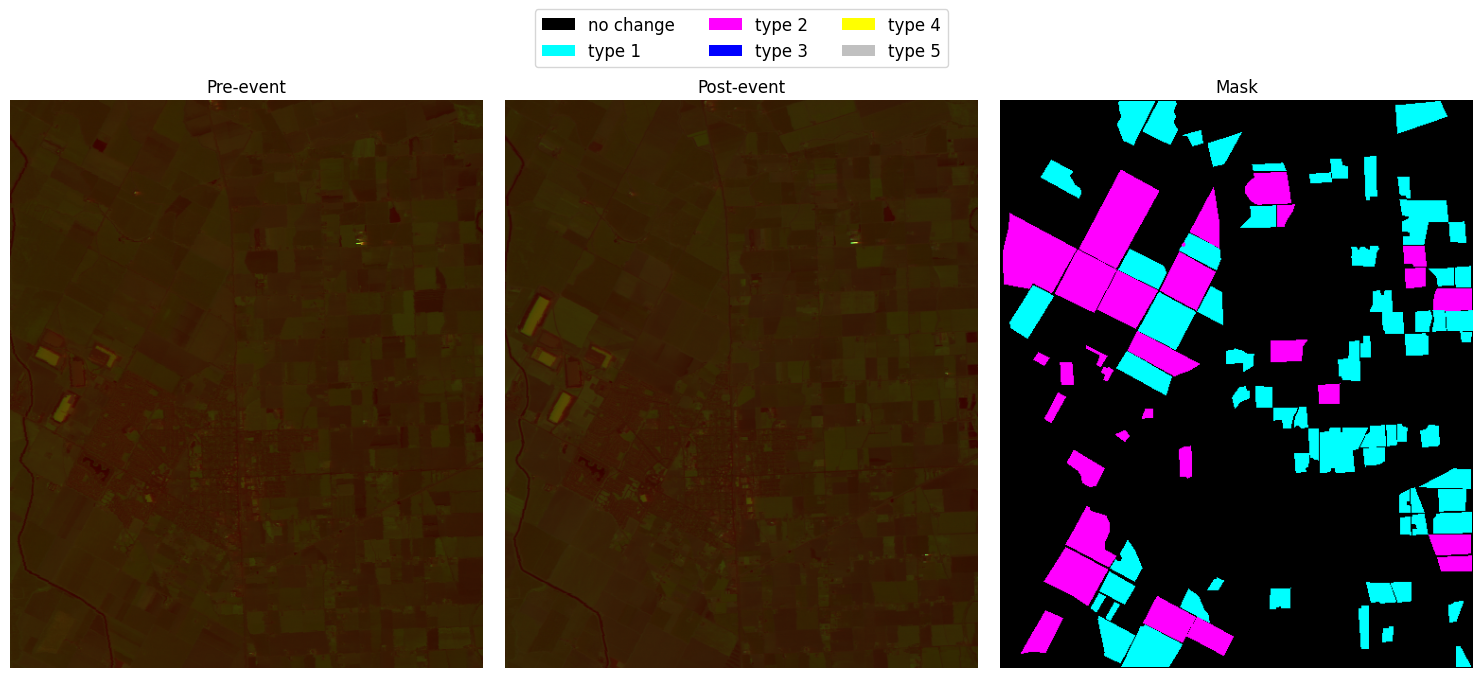

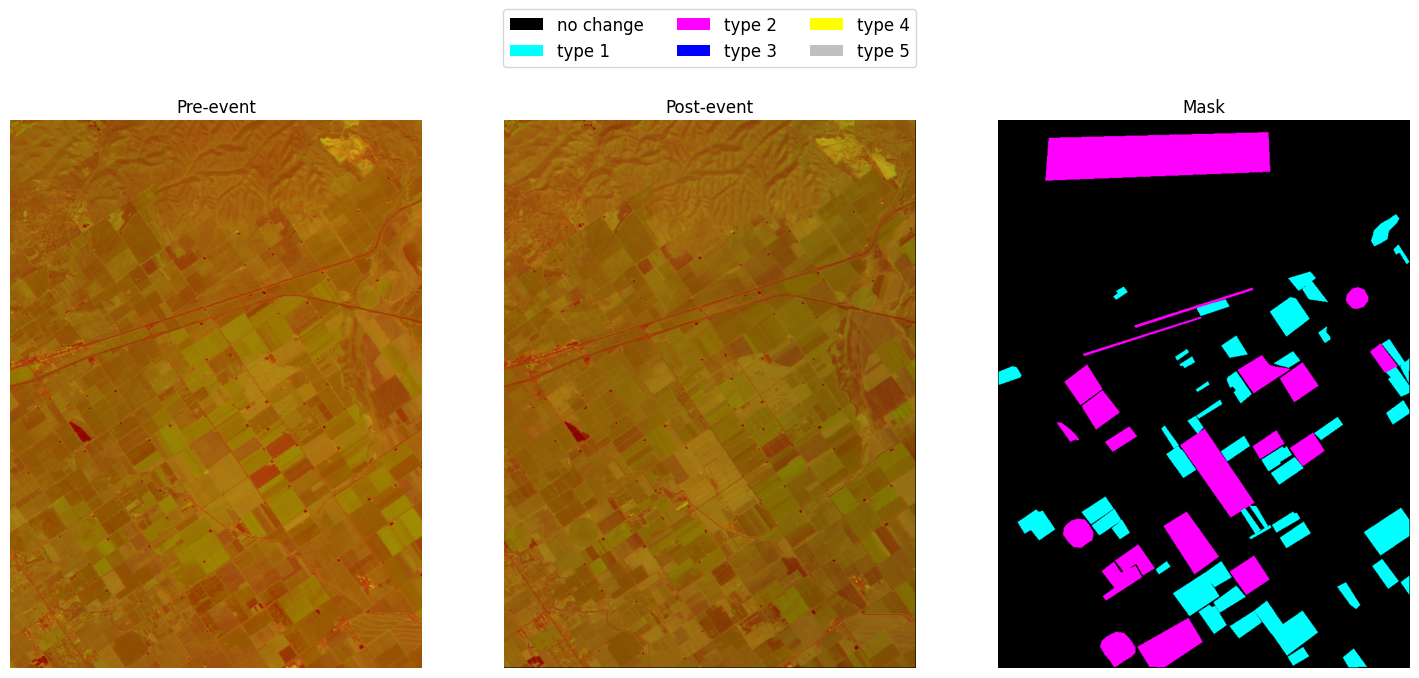

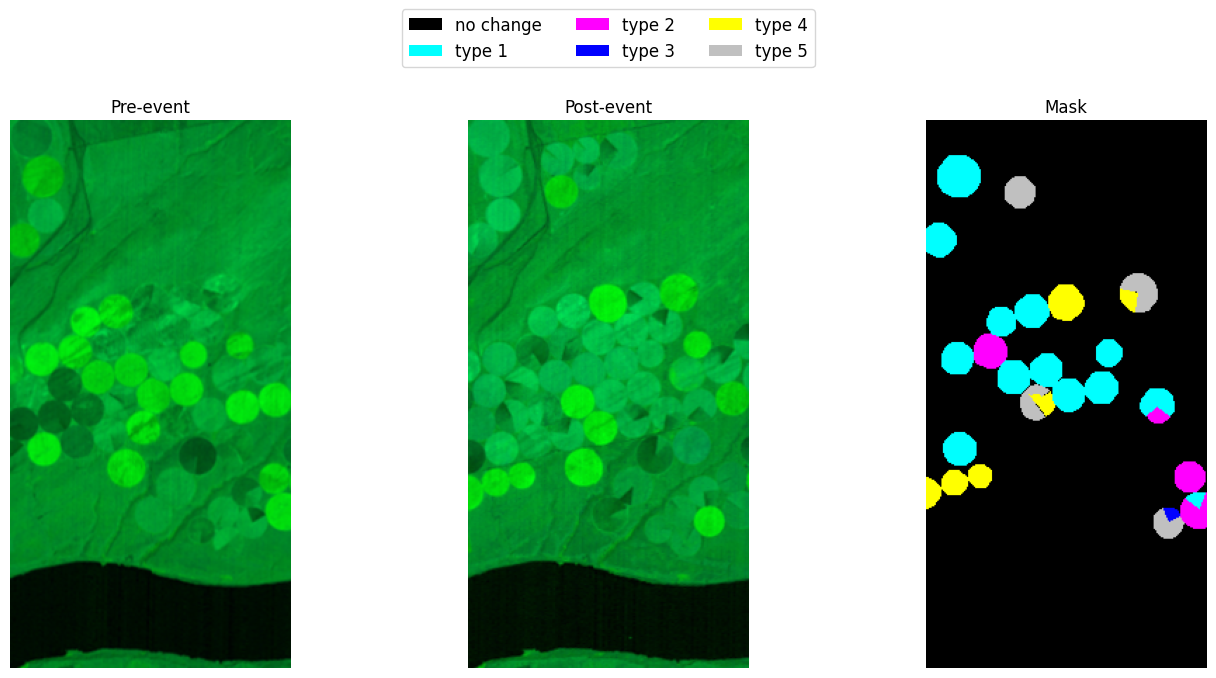

In [ ]:
dataset_config = {
    "data_dir" : "./data/hyperspectral_change_detection/ChangeDetectionDataset-master/",
    "selection": "rgb",
    "task_type": "multilabel"
}
dataset = HyperspectralChangeDetectionDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(0)
dataset.show_image(1)
dataset.show_image(2);

In [7]:
dataset.data_distribution_table()

,Number of pixels
no change,890141.0
type 1,96962.0
type 2,115960.0
type 3,79.0
type 4,1557.0
type 5,1461.0


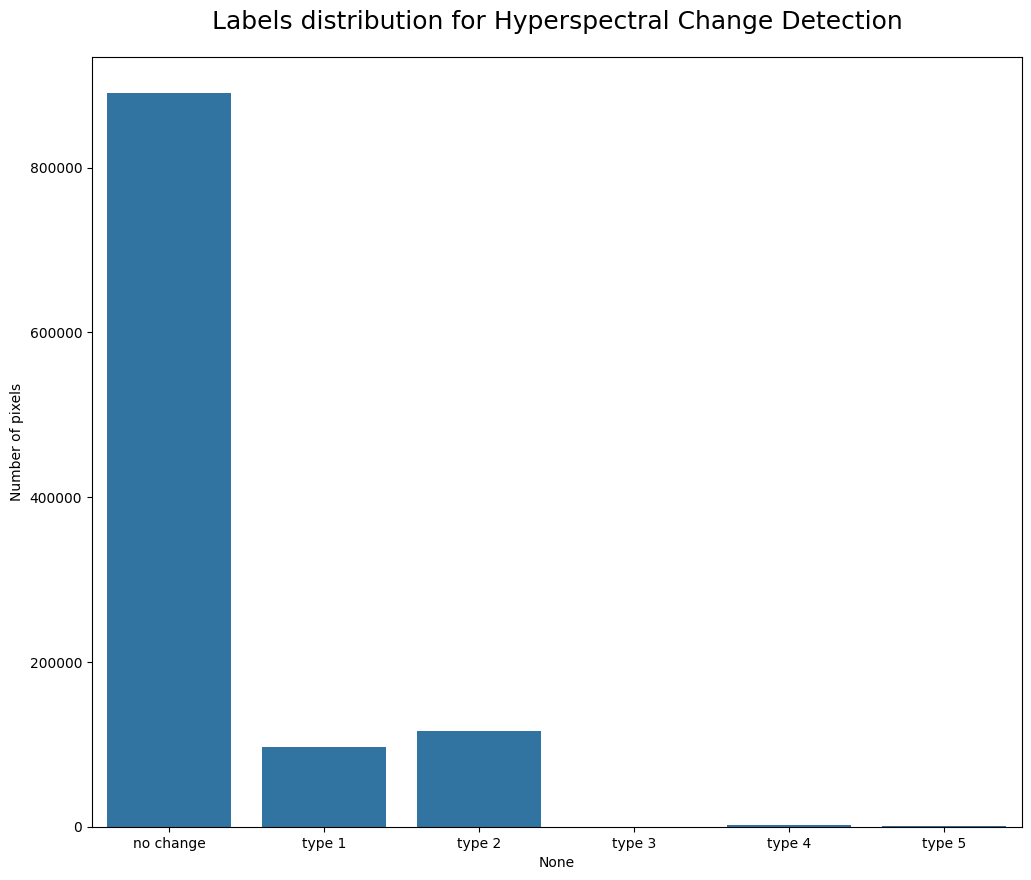

In [8]:
dataset.data_distribution_barchart();

### Binary mask

Total number of patches: 3


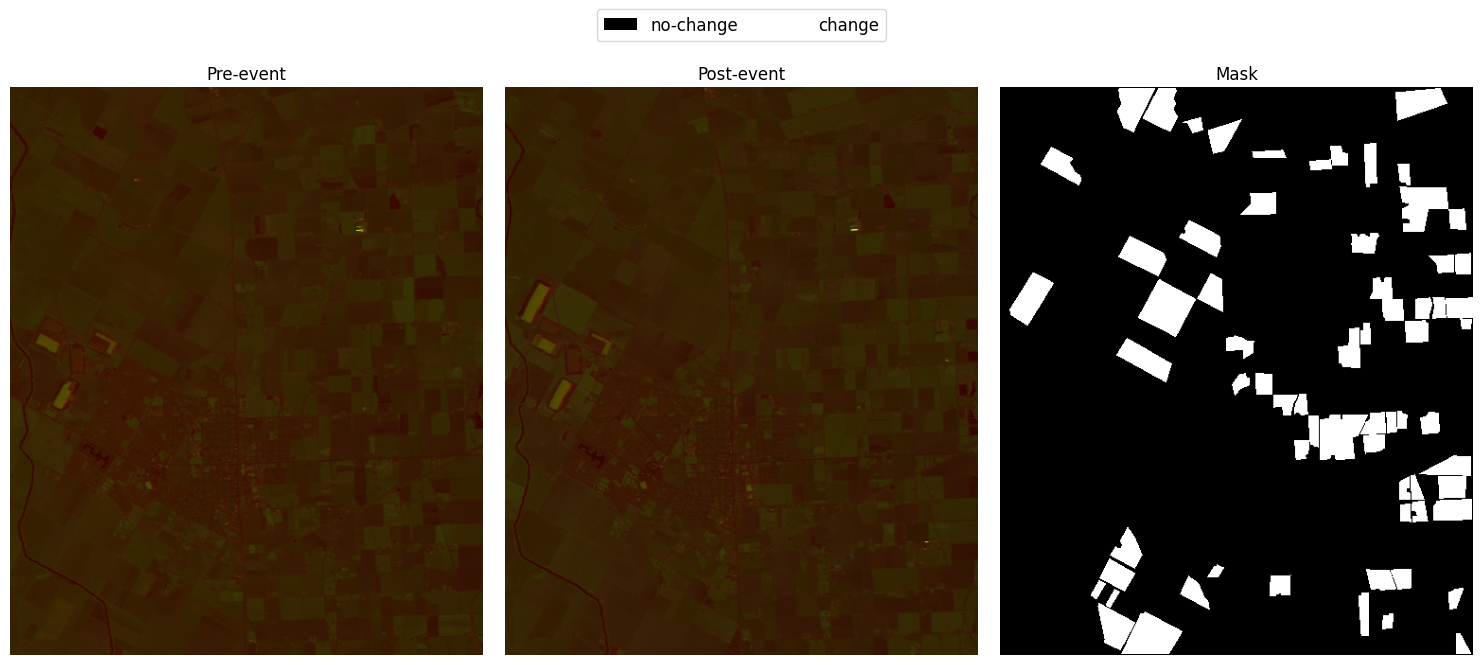

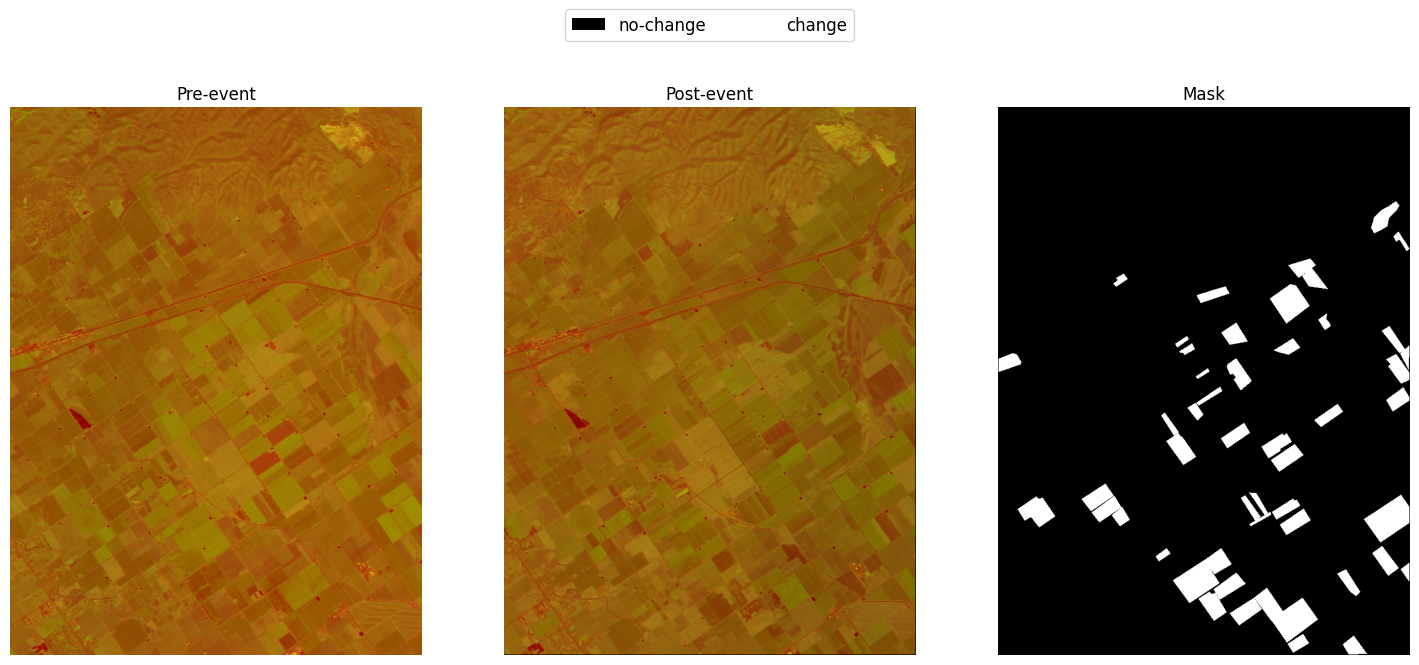

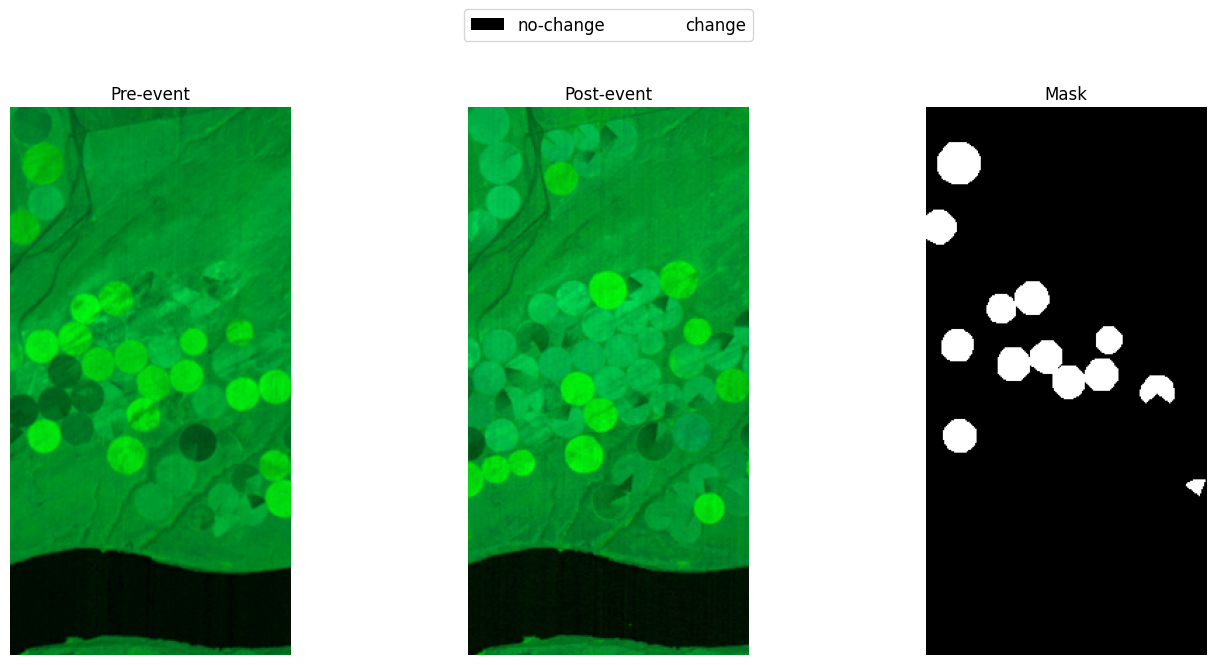

In [ ]:
dataset_config = {
    "data_dir" : "./data/hyperspectral_change_detection/ChangeDetectionDataset-master/",
    "selection": "rgb",
    "task_type": "binary"
}
dataset = HyperspectralChangeDetectionDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(0)
dataset.show_image(1)
dataset.show_image(2);

## Load train and test data

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/hyperspectral_change_detection/ChangeDetectionDataset-master/",
    "selection": "rgb",
    "task_type": "binary",
    "mode": "train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = HyperspectralChangeDetectionDataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/hyperspectral_change_detection/ChangeDetectionDataset-master/",
    "selection": "rgb",
    "task_type": "binary",
    "mode": "val",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = HyperspectralChangeDetectionDataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(1, 1)

## Create the model

In [ ]:
epochs = 50
model_directory = "./data/experiments/hyperspectral_change_detection"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [10]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-26 14:16:49,983 INFO Starting training.
training: 100%|██████████| 1/1 [00:01<00:00,  1.43s/it]
2026-01-26 14:16:51,465 INFO epoch: 1, loss:  0.31282
testing on train set: 100%|██████████| 1/1 [00:01<00:00,  1.08s/it]
2026-01-26 14:16:54,002 INFO Accuracy:0.6035232543945312, Accuracy per Class:[0.29972839 0.90731812], Precision Micro:0.0, Precision Macro:0.0, Precision Weighted:0.0, Precision per Class:[0. 0.], Recall Micro:0.0, Recall Macro:0.0, Recall Weighted:0.0, Recall per Class:[0. 0.], F1_score Micro:0.0, F1_score Macro:0.0, F1_score Weighted:0.0, F1_score per Class:[0. 0.], IOU:0.0, IOU mean:0.0, IOU per Class:[0. 0.]
training: 100%|██████████| 1/1 [00:01<00:00,  1.15s/it]
2026-01-26 14:16:55,158 INFO epoch: 2, loss:  0.31281
testing on train set: 100%|██████████| 1/1 [00:01<00:00,  1.19s/it]
2026-01-26 14:16:56,365 INFO Accuracy:0.6035232543945312, Accuracy per Class:[0.29972839 0.90731812], Precision Micro:0.0, Precision Macro:0.0, Precision Weighted:0.0, Precision pe

## Preditions

2026-01-26 13:55:07,656 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/hyperspectral_change_detection/checkpoint.pth.tar
2026-01-26 13:55:08,046 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/hyperspectral_change_detection/checkpoint.pth.tar at epoch 51


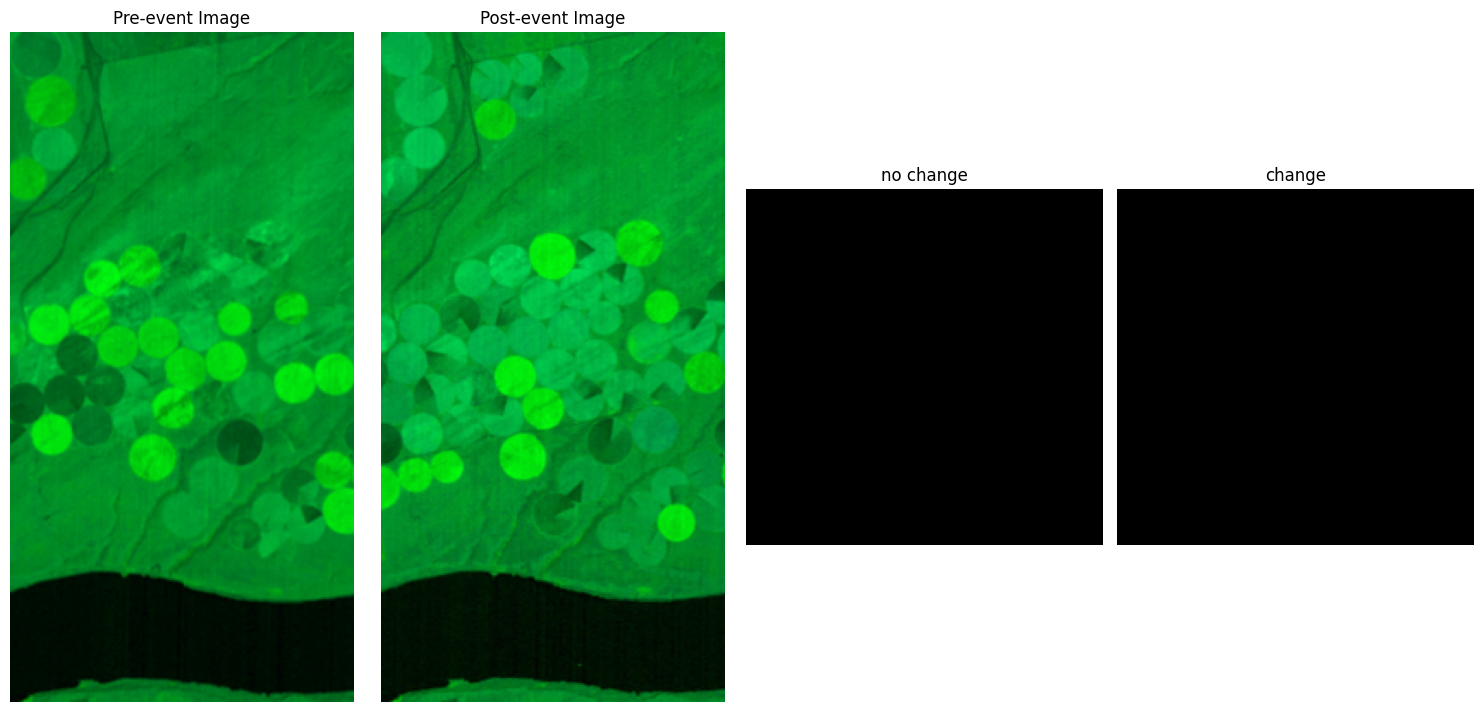

In [ ]:
model_path = "./data/experiments/hyperspectral_change_detection/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

test_dataset_config = {
    "data_dir" : "./data/hyperspectral_change_detection/ChangeDetectionDataset-master/",
    "selection": "rgb",
    "mode": "test",
}
test_dataset = HyperspectralChangeDetectionDataset(test_dataset_config)

image1 = test_dataset[0][0][0]
image2 = test_dataset[0][0][1]
fig = model.predict_masks(image1, image2, labels, transform)